**FairSpeech - Notebook 02**

**Author:** Jaswanth Maradani

**Role:** Data & Statistics Lead

**Objective:** Perform exploratory data analysis (EDA) and data quality assessment on EdAcc.

Outputs:
* Accent distribution analysis
* L1 distribution analysis
* Speaker analysis  
* Transcript analysis  
* Data quality findings  
* Segmentation recommendations  


In [2]:
# Import libraries
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load EdAcc dataset
edacc = load_dataset("edinburghcstr/edacc")

# Convert validation split to dataframe
df = pd.DataFrame(edacc["validation"])

print("Dataset loaded successfully!")
print(df.shape)

README.md:   0%|          | 0.00/6.95k [00:00<?, ?B/s]

data/validation-00000-of-00006-17ec18f4d(…): reconstructing file:   0%|          |  0.00B /  457MB            

data/validation-00000-of-00006-17ec18f4d(…): downloading bytes:           |  0.00B            

data/validation-00001-of-00006-6f3978e4f(…): reconstructing file:   0%|          |  0.00B /  478MB            

data/validation-00001-of-00006-6f3978e4f(…): downloading bytes:           |  0.00B            

...

data/test-00009-of-00010-648ce5002d12449(…): reconstructing file:   0%|          |  0.00B /  299MB            

data/test-00009-of-00010-648ce5002d12449(…): downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/9848 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/9289 [00:00<?, ? examples/s]

Dataset loaded successfully!
(9848, 7)


In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

edacc = load_dataset("edinburghcstr/edacc")
df = pd.DataFrame(edacc["validation"])

print(df.shape)

(9848, 7)


In [2]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nUnique Speakers:")
print(df["speaker"].nunique())

print("\nUnique Accents:")
print(df["accent"].nunique())

print("\nUnique Raw Accents:")
print(df["raw_accent"].nunique())

print("\nUnique L1 Languages:")
print(df["l1"].nunique())

Rows: 9848
Columns: 7

Unique Speakers:
62

Unique Accents:
25

Unique Raw Accents:
50

Unique L1 Languages:
29


In [3]:
df["accent"].value_counts()

,count
accent,
Southern British English,1190
Mainstream US English,1096
Irish English,964
Eastern European,862
Italian,602
Don't know,586
Egyptian,469
Vietnamese,463
Chinese,447


In [4]:
df["l1"].value_counts()

,count
l1,
Southern British English,1062
Irish English,964
Romanian,862
Catalan,598
Mandarin,531
Polish,528
Arabic,469
Vietnamese,463
Italian,458


In [5]:
df["speaker"].value_counts().describe()

,count
count,62.000000
mean,158.838710
std,89.001417
min,27.000000
25%,98.000000
50%,131.000000
75%,221.500000
max,434.000000


In [6]:
ignore_segments = df[
    df["text"].str.contains(
        "IGNORE_TIME_SEGMENT",
        na=False
    )
]

print(ignore_segments.shape)

(62, 7)


**Accent Distribution Plot**

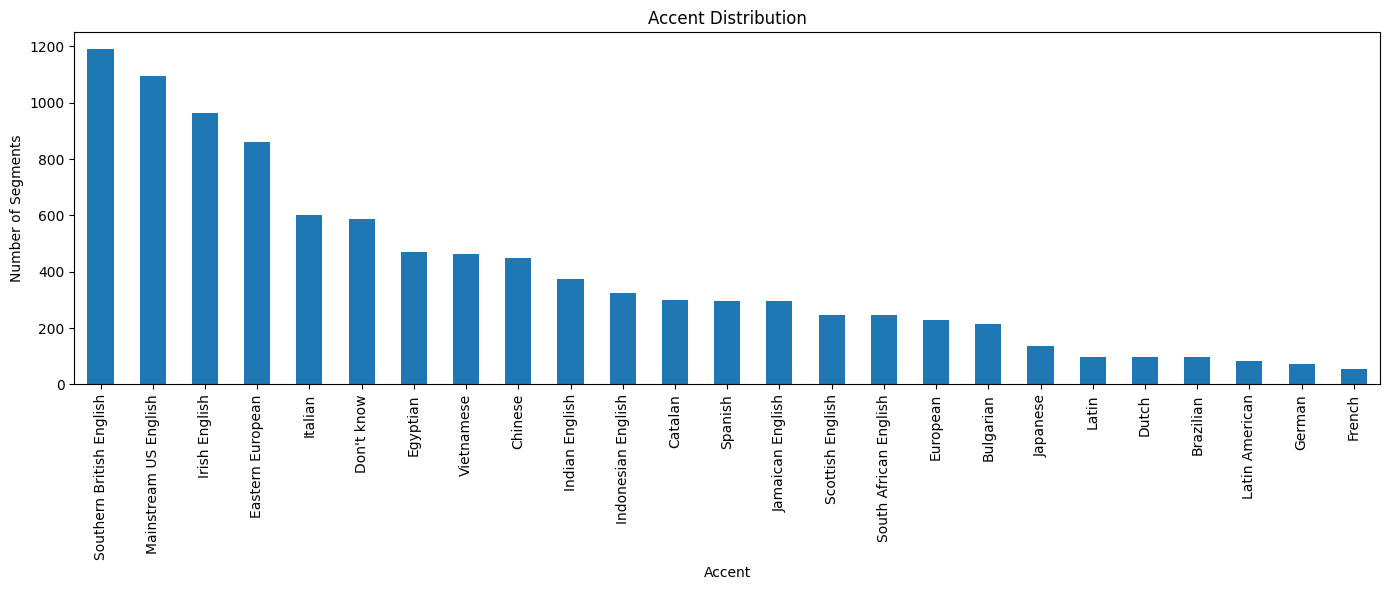

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

df["accent"].value_counts().plot(
    kind="bar"
)

plt.title("Accent Distribution")
plt.xlabel("Accent")
plt.ylabel("Number of Segments")
plt.tight_layout()

plt.show()

**L1 Distribution Plot**

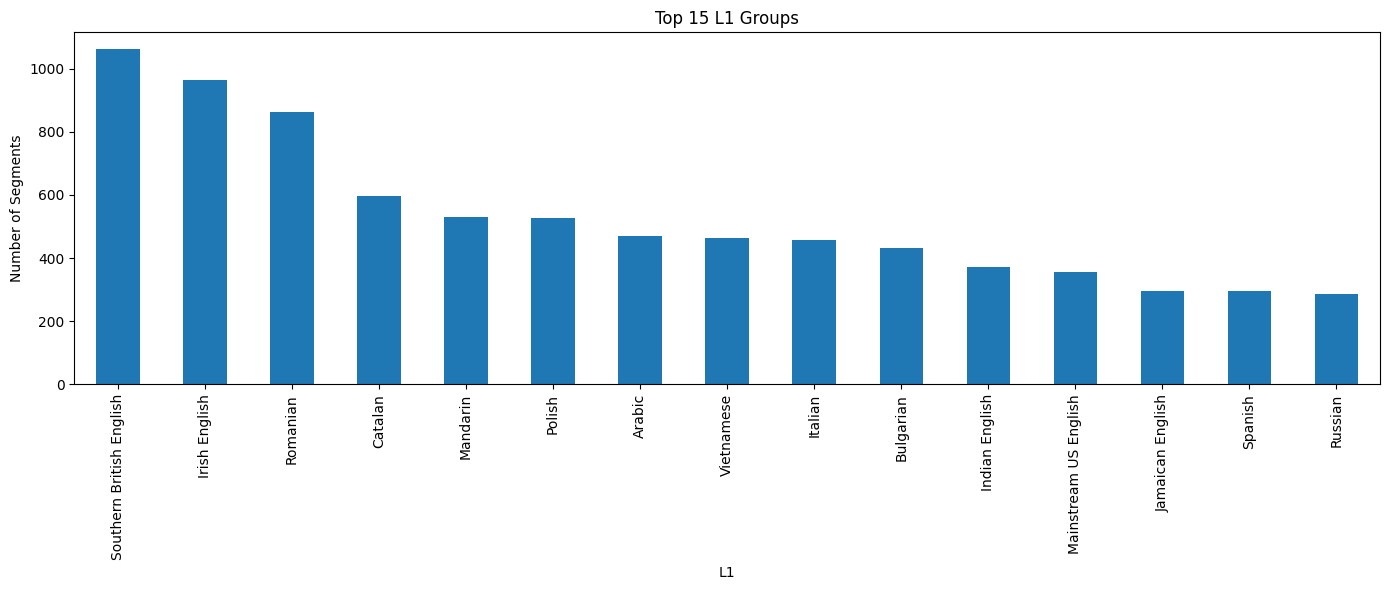

In [8]:
plt.figure(figsize=(14,6))

df["l1"].value_counts().head(15).plot(
    kind="bar"
)

plt.title("Top 15 L1 Groups")
plt.xlabel("L1")
plt.ylabel("Number of Segments")
plt.tight_layout()

plt.show()

**Word Count Analysis**

In [9]:
df["word_count"] = (
    df["text"]
    .astype(str)
    .apply(lambda x: len(x.split()))
)

In [10]:
df["word_count"].describe()

,word_count
count,9848.000000
mean,15.158103
std,24.296213
min,1.000000
25%,2.000000
50%,7.000000
75%,18.000000
max,383.000000


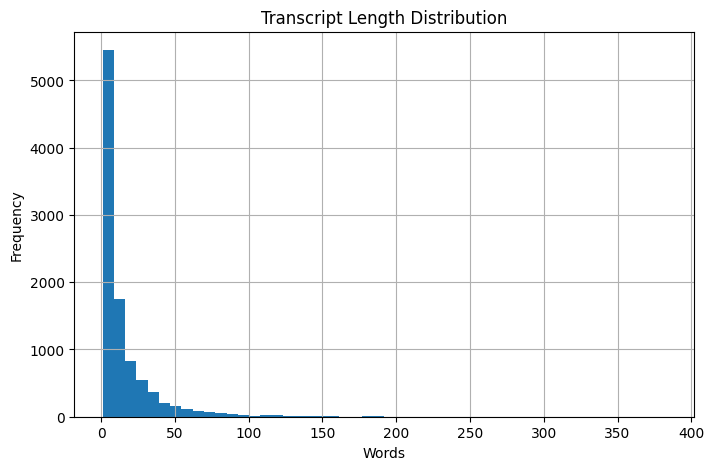

In [11]:
df["word_count"].hist(
    bins=50,
    figsize=(8,5)
)

plt.title("Transcript Length Distribution")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

In [12]:
ignore_segments = df[
    df["text"].str.contains(
        "IGNORE_TIME_SEGMENT",
        na=False
    )
]

print(ignore_segments.shape)

(62, 8)


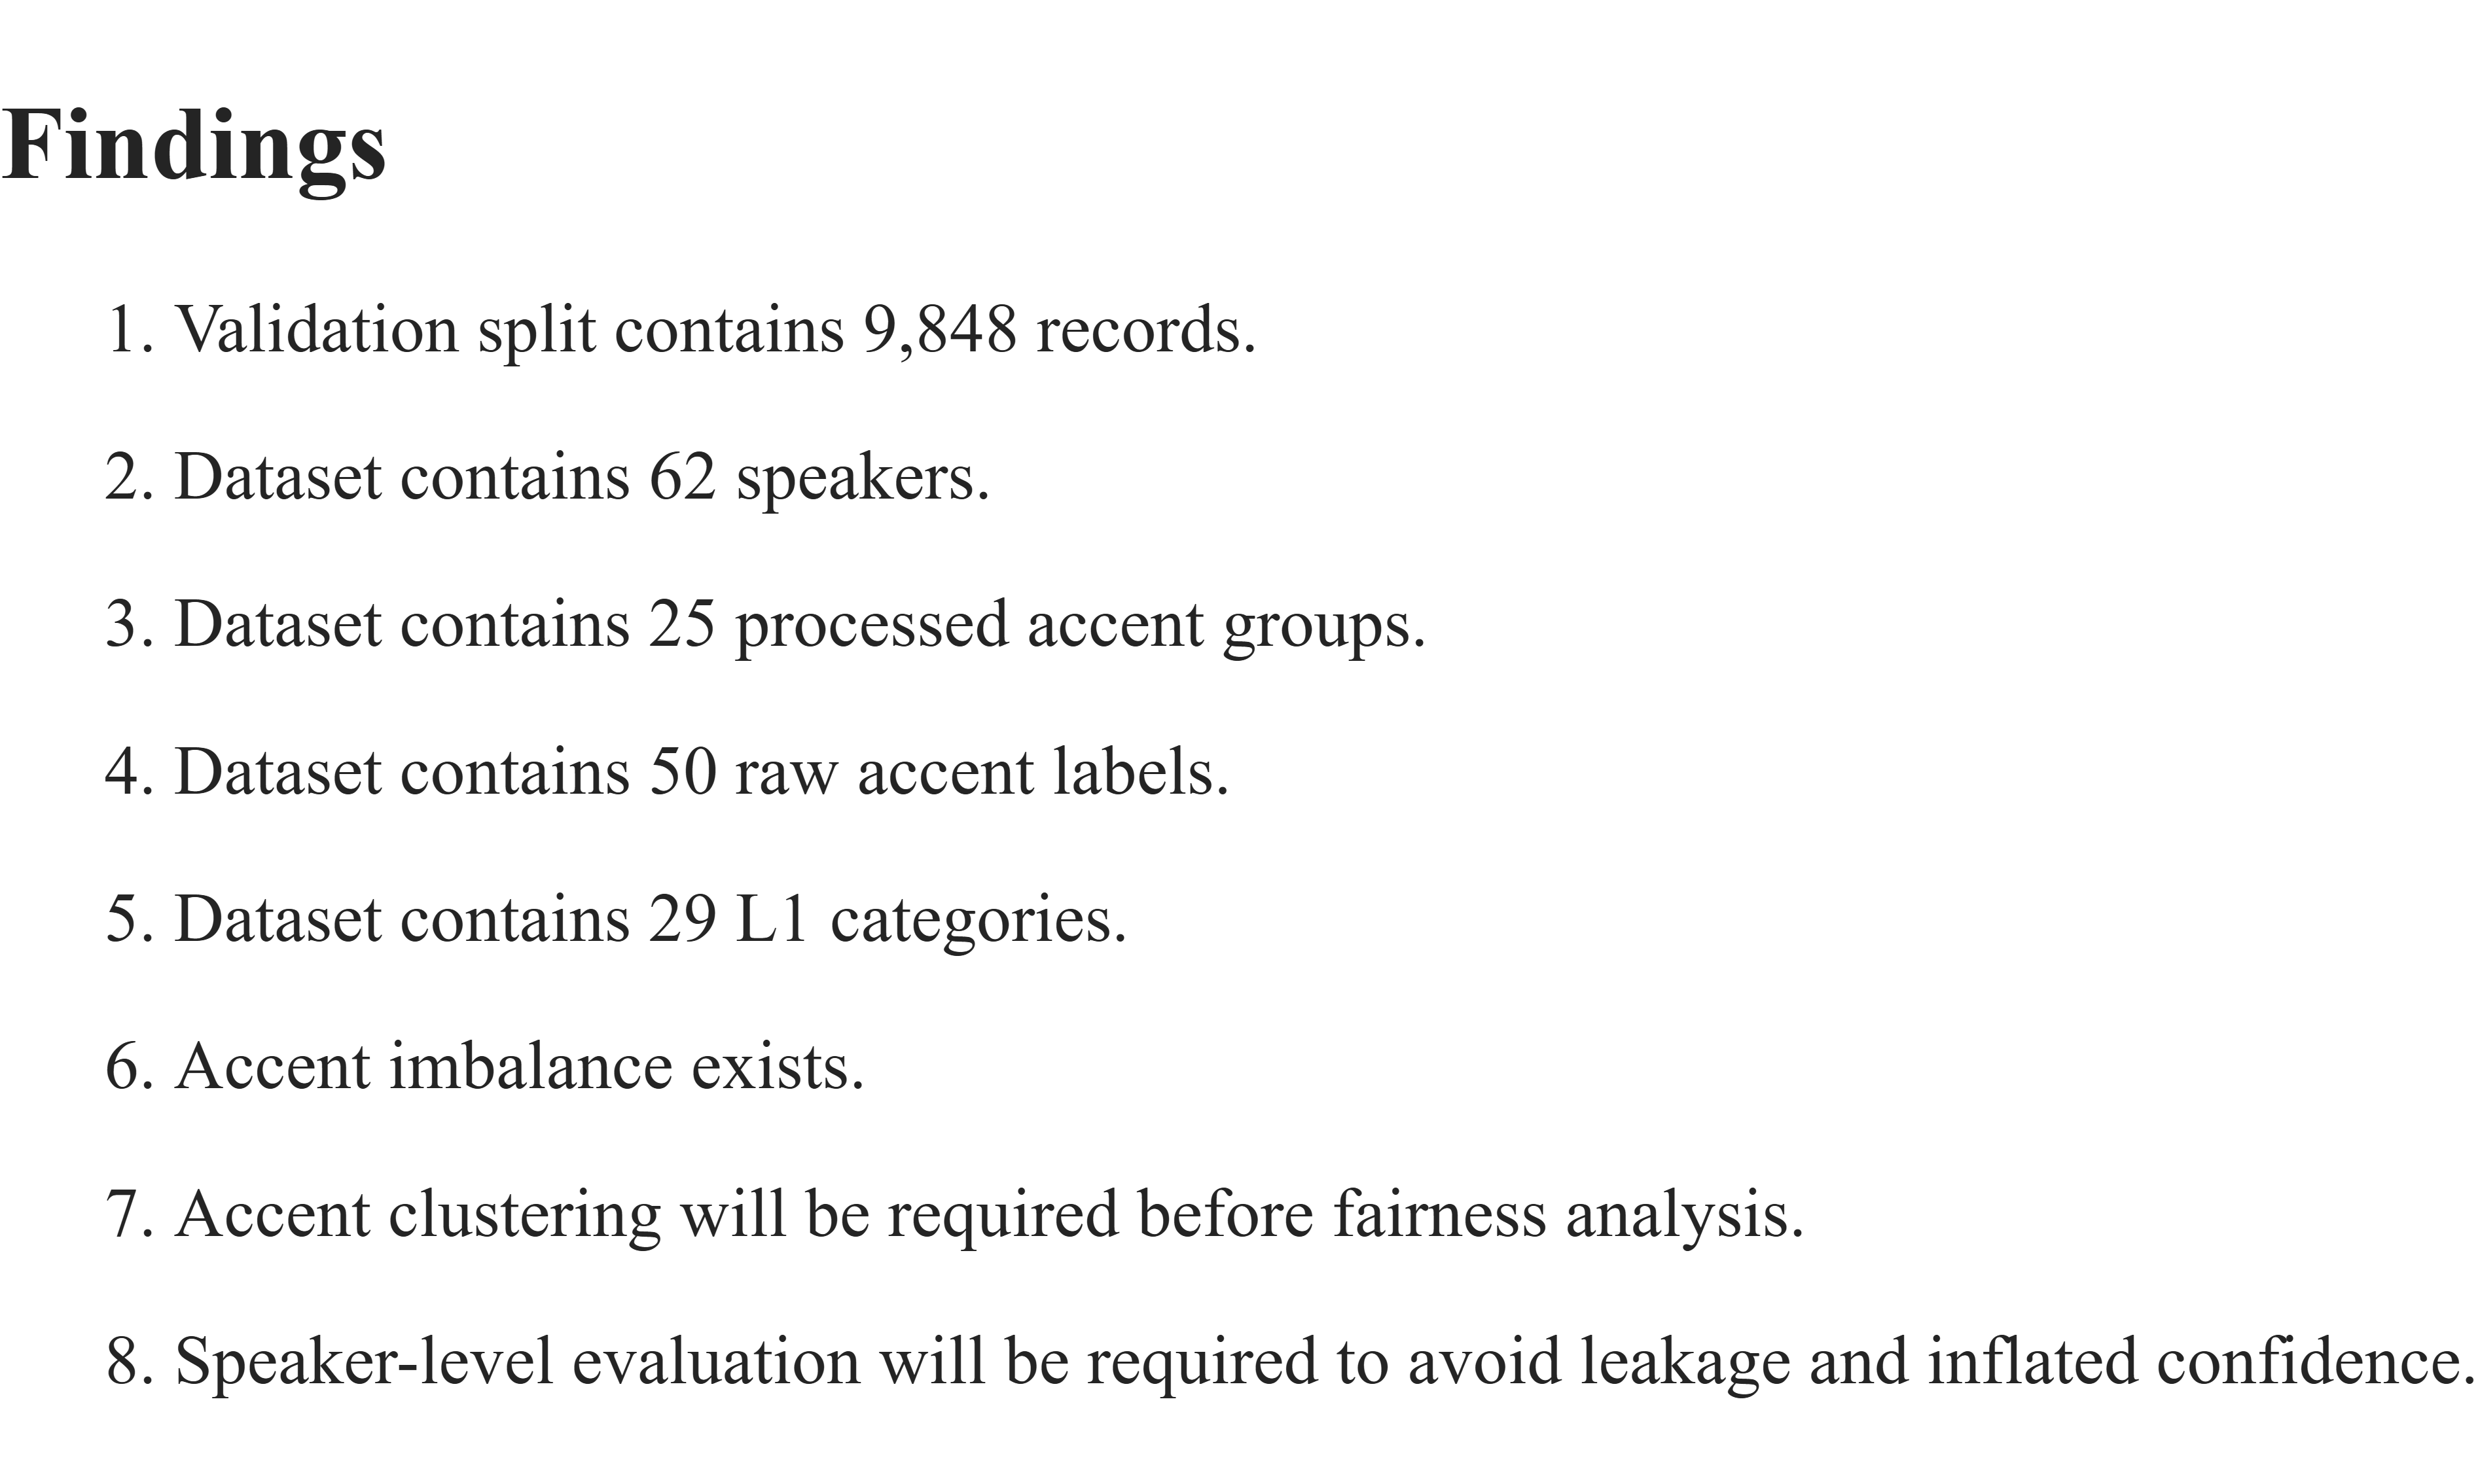